# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [5]:
VARIANT = 20   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 20 уже на месте: /content/data/variant_20
данные варианта: /content/data/variant_20
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 4.14.0 | numpy 2.4.6 | pandas 2.2.3


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [7]:
# TODO: прочитайте variant.json и напечатайте его.
# Подсказка: путь собирайте от DATA_DIR, это объект Path, а не строка:
#   (DATA_DIR / "variant.json").read_text(encoding="utf-8") даёт текст файла,
#   json.loads(...) превращает текст в словарь.
import json
import pandas as pd
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(variant_info)

# TODO: прочитайте labels.csv в DataFrame labels и покажите первые строки.
# Путь к файлу: DATA_DIR / "labels.csv"
labels = labels = pd.read_csv(DATA_DIR / "labels.csv")
labels.head()


{'variant': 20, 'dataset_version': 'v1', 'source': 'release', 'breeds': ['Ragdoll', 'Sphynx', 'american_bulldog', 'boxer'], 'species': {'Ragdoll': 'cat', 'Sphynx': 'cat', 'american_bulldog': 'dog', 'boxer': 'dog'}, 'class_ids': {'Ragdoll': 0, 'Sphynx': 1, 'american_bulldog': 2, 'boxer': 3}, 'names_ru': {'Ragdoll': 'рэгдолл', 'Sphynx': 'сфинкс', 'american_bulldog': 'американский бульдог', 'boxer': 'боксёр'}, 'n_images': 806, 'n_boxes': 403, 'n_trimaps': 806, 'per_breed': {'Ragdoll': {'images': 203, 'boxes': 101, 'trimaps': 203}, 'Sphynx': {'images': 201, 'boxes': 101, 'trimaps': 201}, 'american_bulldog': {'images': 201, 'boxes': 101, 'trimaps': 201}, 'boxer': {'images': 201, 'boxes': 100, 'trimaps': 201}}, 'dataset': 'Oxford-IIIT Pet', 'dataset_url': 'https://www.robots.ox.ac.uk/~vgg/data/pets/', 'license': 'CC BY-SA 4.0', 'citation': 'O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V. Jawahar. Cats and Dogs. IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 2012.'}


,filename,breed,species,class_id
0,american_bulldog_2.jpg,american_bulldog,dog,2
1,american_bulldog_3.jpg,american_bulldog,dog,2
2,american_bulldog_5.jpg,american_bulldog,dog,2
3,american_bulldog_6.jpg,american_bulldog,dog,2
4,american_bulldog_7.jpg,american_bulldog,dog,2


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

In [8]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)
bgr = cv2.imread(str(example_path))
print("Type:", type(bgr))
print("Shape:", bgr.shape)
print("Dtype:", bgr.dtype)
print("Min/Max:", bgr.min(), bgr.max())
center_y, center_x = bgr.shape[0] // 2, bgr.shape[1] // 2
print("Пиксель в центре:", bgr[center_y, center_x])
# TODO: прочитайте файл через cv2.imread(str(example_path)) в переменную bgr
# TODO: напечатайте type, shape, dtype, min, max и значение пикселя в центре кадра
#       bgr[bgr.shape[0] // 2, bgr.shape[1] // 2]


Sphynx_5.jpg
Type: <class 'numpy.ndarray'>
Shape: (390, 600, 3)
Dtype: uint8
Min/Max: 0 255
Пиксель в центре: [ 74  82 135]


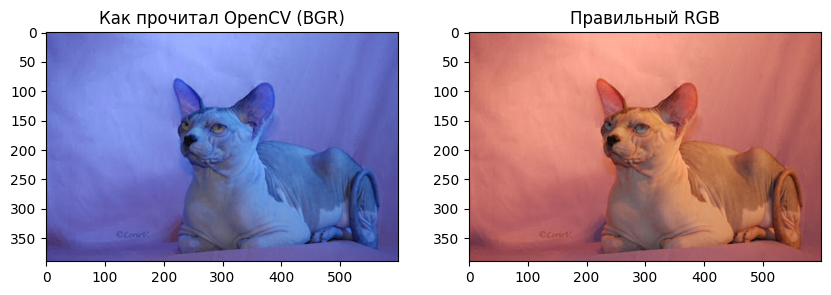

In [9]:
import matplotlib.pyplot as plt
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(bgr)
plt.title("Как прочитал OpenCV (BGR)")

plt.subplot(1, 2, 2)
plt.imshow(rgb)
plt.title("Правильный RGB")
plt.show()

Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [10]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)
print("Gray shape:", gray.shape)
print("Resized shape:", resized.shape)
print("Flipped shape:", flipped.shape)

Gray shape: (390, 600)
Resized shape: (224, 224, 3)
Flipped shape: (390, 600, 3)


In [11]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


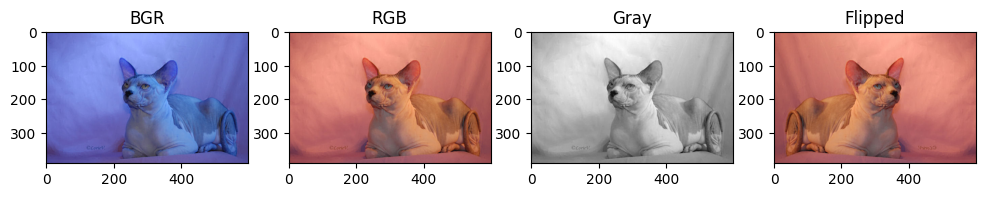

In [12]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 4, 1)
plt.imshow(bgr)
plt.title("BGR")
plt.subplot(1, 4, 2)
plt.imshow(rgb)
plt.title("RGB")
plt.subplot(1, 4, 3)
plt.imshow(gray, cmap="gray")
plt.title("Gray")
plt.subplot(1, 4, 4)
plt.imshow(flipped)
plt.title("Flipped")
plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()


## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [13]:
label_by_file = labels.set_index("filename")
rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"] = im.width
        rec["height"] = im.height

    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()
    if p.name in label_by_file.index:
        rec["breed"] = label_by_file.loc[p.name, "breed"]
        rec["species"] = label_by_file.loc[p.name, "species"]
    else:
        rec["breed"] = None
        rec["species"] = None

    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Ragdoll_1.jpg,.jpg,JPEG,RGB,183,275,True,Ragdoll,cat
1,Ragdoll_10.jpg,.jpg,JPEG,RGB,500,375,True,Ragdoll,cat
2,Ragdoll_100.jpg,.jpg,JPEG,RGB,461,364,True,Ragdoll,cat
3,Ragdoll_101.jpg,.jpg,JPEG,RGB,333,500,True,Ragdoll,cat
4,Ragdoll_103.jpg,.jpg,JPEG,RGB,500,309,True,Ragdoll,cat


In [14]:
summary = {
    "variant": 20,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
    "n_cats": (info["species"] == "cat").sum(),
    "n_dogs": (info["species"] == "dog").sum(),
    "min_width": info["width"].min(),
    "median_width": info["width"].median(),
    "max_width": info["width"].max(),
    "min_height": info["height"].min(),
    "median_height": info["height"].median(),
    "max_height": info["height"].max(),
    "n_not_rgb": (info["mode"] != "RGB").sum(),
    "n_fake_jpeg": ((info["ext"].isin([".jpg", ".jpeg"])) & (info["pil_format"] != "JPEG")).sum(),
    "n_with_xml": info["has_xml"].sum()
}
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,20.0
1,n_files,806.0
2,n_breeds,4.0
3,n_cats,404.0
4,n_dogs,402.0
5,min_width,161.0
6,median_width,500.0
7,max_width,1075.0
8,min_height,168.0
9,median_height,375.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [15]:
bad_mode = info[info["mode"] != "RGB"]
print("Файлы не в RGB:", len(bad_mode))
print(bad_mode[["filename", "mode"]])
bad_ext = info[info["ext"].isin([".jpg", ".jpeg"]) & (info["pil_format"] != "JPEG")]
print("\nФайлы с неверным форматом:", len(bad_ext))
print(bad_ext[["filename", "ext", "pil_format"]])


Файлы не в RGB: 0
Empty DataFrame
Columns: [filename, mode]
Index: []

Файлы с неверным форматом: 0
Empty DataFrame
Columns: [filename, ext, pil_format]
Index: []


In [16]:
test_p = IMG_DIR / info["filename"].iloc[0]
img_normal = cv2.imread(str(test_p))
img_unchanged = cv2.imread(str(test_p), cv2.IMREAD_UNCHANGED)

print("Файл: ", test_p.name)
print("Обычное чтение shape: ", img_normal.shape)
print("IMREAD_UNCHANGED shape: ", img_unchanged.shape)

Файл:  Ragdoll_1.jpg
Обычное чтение shape:  (275, 183, 3)
IMREAD_UNCHANGED shape:  (275, 183, 3)


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [17]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]
xml_file = info[info["has_xml"] == True]["filename"].iloc[0]
xml_path = XML_DIR / (Path(xml_file).stem + ".xml")
img_path = IMG_DIR / xml_file
boxes = read_boxes(xml_path)
print("Файл:", xml_file)
print("Боксы (xmin, ymin, xmax, ymax):", boxes)

trimap_path = TRIMAP_DIR / (Path(xml_file).stem + ".png")
trimap = cv2.imread(str(trimap_path), cv2.IMREAD_UNCHANGED)
print("Уникальные значения trimap:", np.unique(trimap))

Файл: Ragdoll_1.jpg
Боксы (xmin, ymin, xmax, ymax): [(63, 29, 131, 97)]
Уникальные значения trimap: [1 2 3]


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

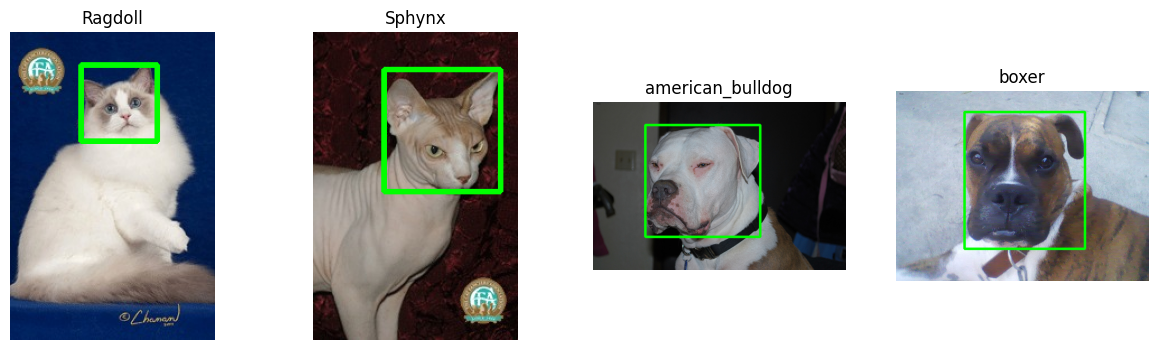

In [18]:
breeds = info[info["has_xml"] == True]["breed"].unique()
n_breeds = len(breeds)

plt.figure(figsize=(15, 4))
for i, breed in enumerate(breeds):
    row = info[(info["breed"] == breed) & (info["has_xml"] == True)].iloc[0]
    img_p = IMG_DIR / row["filename"]
    xml_p = XML_DIR / (Path(row["filename"]).stem + ".xml")
    img_bgr = cv2.imread(str(img_p))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    boxes = read_boxes(xml_p)
    for (x0, y0, x1, y1) in boxes:
        cv2.rectangle(img_rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)

    plt.subplot(1, n_breeds, i + 1)
    plt.imshow(img_rgb)
    plt.title(breed)
    plt.axis("off")

plt.savefig(RESULTS / "samples_grid.png", dpi=110, bbox_inches='tight')
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

In [ ]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)